# Assignment 2
# Loan Eligibility Prediction
Dataset loading, cleaning, preprocessing, feature engineering and EDA.




In [ ]:
#Loan Eligibility Prediction: Dataset Selection, Preprocessing, EDA and Feature Engineering
#Import Libraries


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

# **Uploading Dataset**

In [ ]:
#upoading dataset
df = pd.read_csv("/content/Loan Eligibility Prediction.csv")
print("Shape:", df.shape)
df.head()

Shape: (614, 13)


,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


# **Information about dataset*

In [ ]:
# Basic Data Understanding
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         614 non-null    int64  
 1   Gender              614 non-null    object 
 2   Married             614 non-null    object 
 3   Dependents          614 non-null    int64  
 4   Education           614 non-null    object 
 5   Self_Employed       614 non-null    object 
 6   Applicant_Income    614 non-null    int64  
 7   Coapplicant_Income  614 non-null    float64
 8   Loan_Amount         614 non-null    int64  
 9   Loan_Amount_Term    614 non-null    int64  
 10  Credit_History      614 non-null    int64  
 11  Property_Area       614 non-null    object 
 12  Loan_Status         614 non-null    object 
dtypes: float64(1), int64(6), object(6)
memory usage: 62.5+ KB


,count,mean,std,min,25%,50%,75%,max
Customer_ID,614.0,307.500000,177.390811,1.0,154.25,307.5,460.75,614.0
Dependents,614.0,0.856678,1.216651,0.0,0.00,0.0,2.00,4.0
Applicant_Income,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0
Coapplicant_Income,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0
Loan_Amount,614.0,142.022801,87.083089,9.0,98.00,125.0,164.75,700.0
Loan_Amount_Term,614.0,338.892508,69.716355,12.0,360.00,360.0,360.00,480.0
Credit_History,614.0,0.850163,0.357203,0.0,1.00,1.0,1.00,1.0


In [ ]:
# Unique values in each categorical column
cat_cols = df.select_dtypes(include=["object", "string"]).columns
for col in cat_cols:
    print(col, "->", df[col].unique())

Gender -> ['Female' 'Male']
Married -> ['No' 'Yes']
Education -> ['Graduate' 'Not Graduate']
Self_Employed -> ['No' 'Yes']
Property_Area -> ['Urban' 'Semiurban' 'Rural']
Loan_Status -> ['N' 'Y']


#**Data Cleaning**
Checked for missing values, duplicate rows and hidden zero

In [ ]:
#  Handling Missing Values


print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Customer_ID           0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
Applicant_Income      0
Coapplicant_Income    0
Loan_Amount           0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

Total missing values: 0


In [ ]:
# Hidden missing values: zeros that should not be zero
print("Applicant_Income == 0 :", (df["Applicant_Income"] == 0).sum())
print("Loan_Amount == 0      :", (df["Loan_Amount"] == 0).sum())
print("Coapplicant_Income == 0 (valid):", (df["Coapplicant_Income"] == 0).sum())

Applicant_Income == 0 : 0
Loan_Amount == 0      : 0
Coapplicant_Income == 0 (valid): 273


In [ ]:
# Imputation. This dataset has no nulls, so nothing changes, but the same code works if null exist

num_cols = df.select_dtypes(include=np.number).columns.drop("Customer_ID")
cat_cols = df.select_dtypes(include=["object", "string"]).columns



In [ ]:
# Numerical columns: median (robust to outliers; use mean if the data is symmetric)
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

In [ ]:
# Categorical columns: mode
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
print("Missing values after imputation:", df.isnull().sum().sum())

Missing values after imputation: 0


In [ ]:
# Duplicates and Irrelevant Columns


print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Customer_ID is only an identifier, so it has no predictive value
df = df.drop(columns=["Customer_ID"])
df.shape

Duplicate rows: 0


(614, 12)

# **Exploratory Data Analysis**

Loan_Status
Y    422
N    192
Name: count, dtype: int64
Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


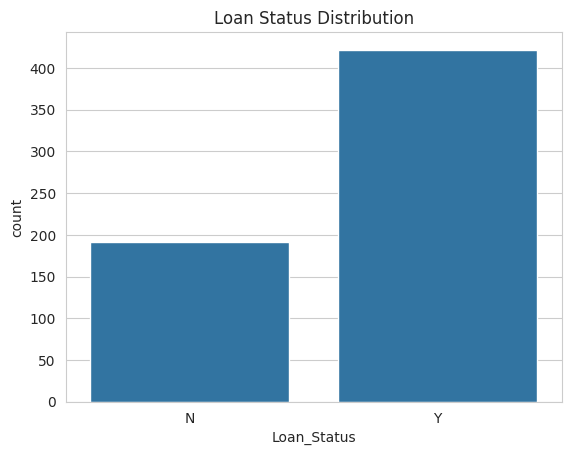

In [ ]:
# Exploratory Data Analysis (EDA)


#Target Variable Distribution


print(df["Loan_Status"].value_counts())
print(df["Loan_Status"].value_counts(normalize=True).round(3))
sns.countplot(x="Loan_Status", data=df)
plt.title("Loan Status Distribution")
plt.show()

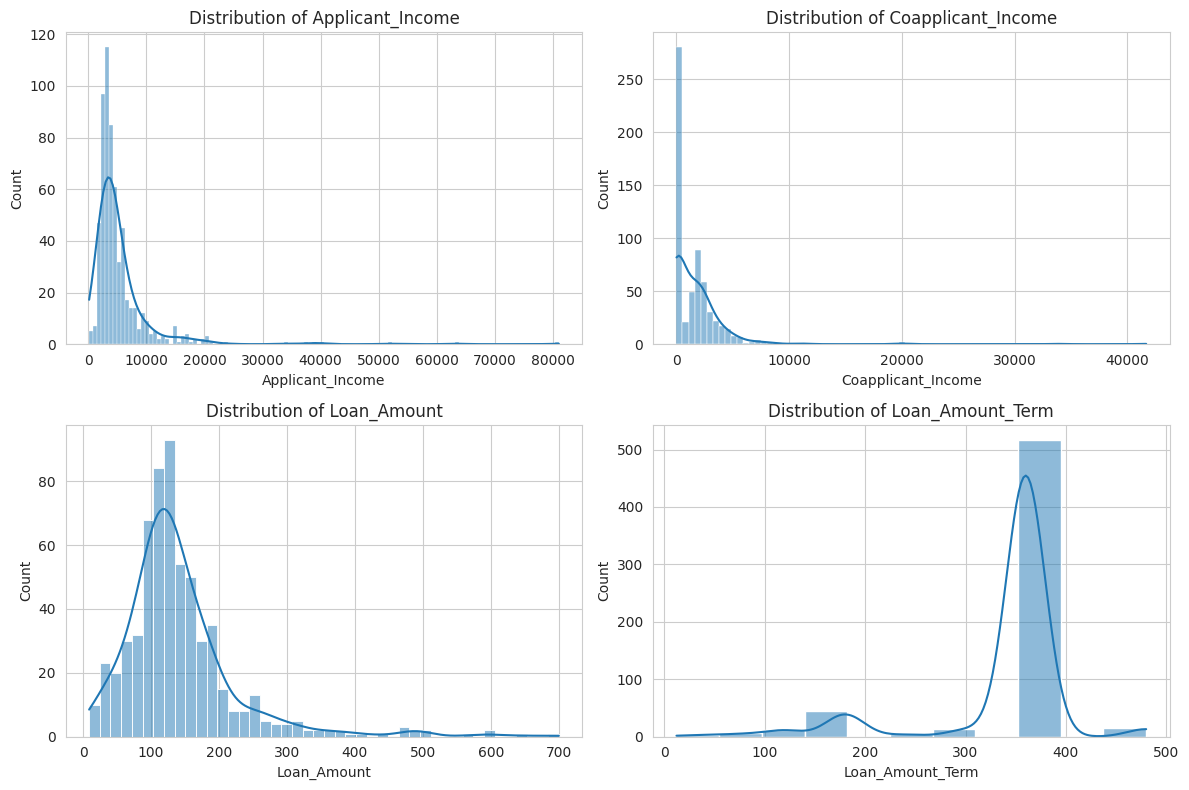

Skewness:
Applicant_Income      6.54
Coapplicant_Income    7.49
Loan_Amount           2.50
Loan_Amount_Term     -2.22
dtype: float64


In [ ]:
#Numerical Features: Distributions


num_features = ["Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Loan_Amount_Term"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_features):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

print("Skewness:")
print(df[num_features].skew().round(2))

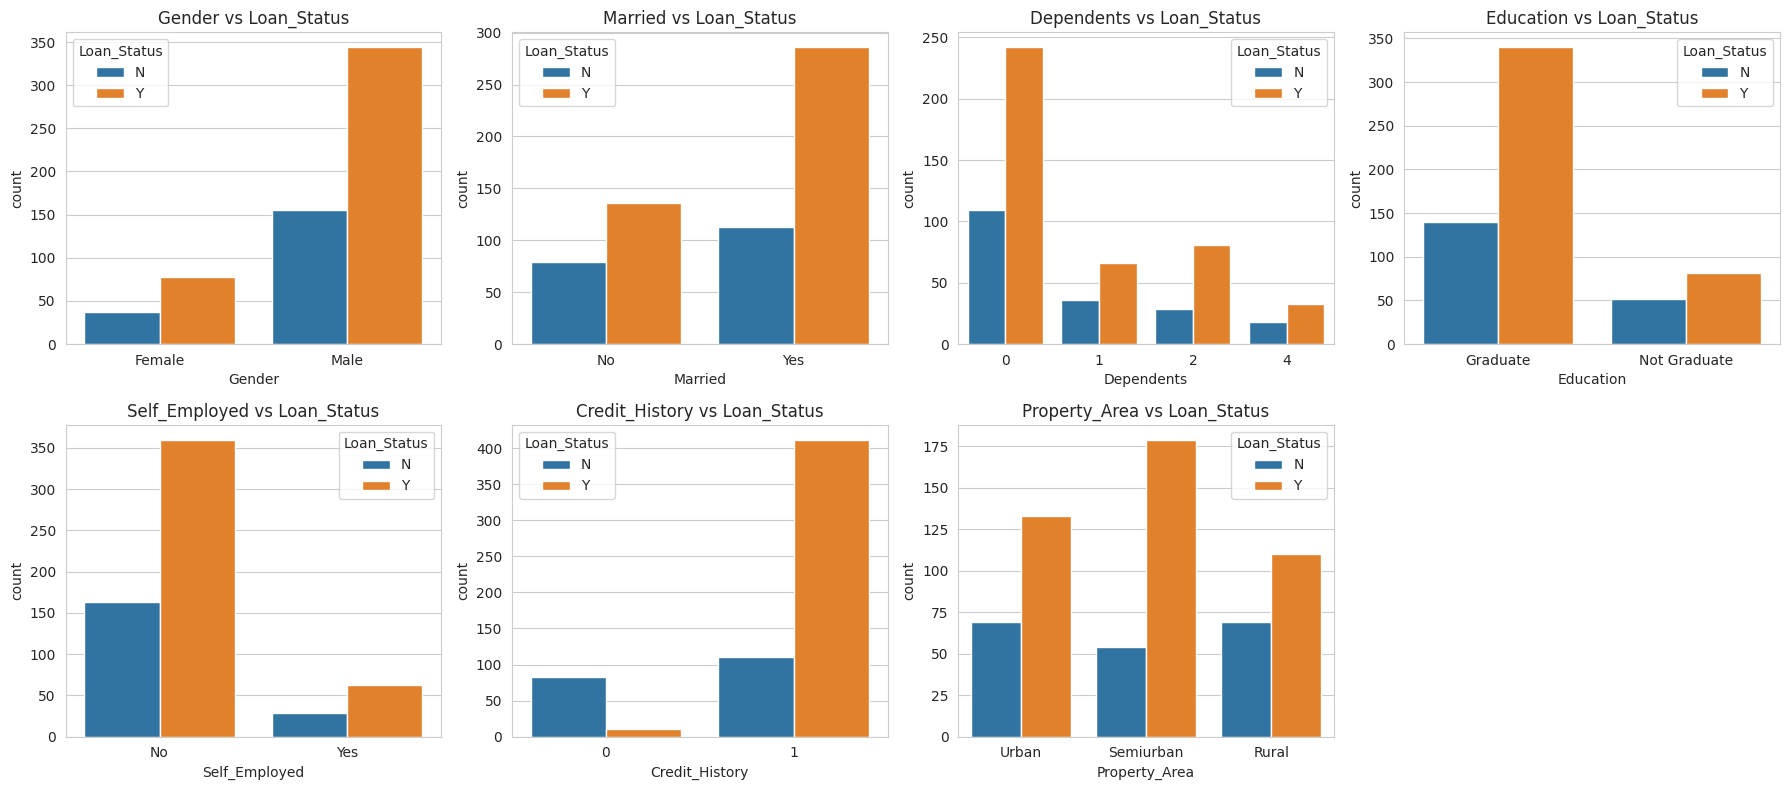

In [ ]:
 #Categorical Features vs Loan Status


cat_features = ["Gender", "Married", "Dependents", "Education",
                "Self_Employed", "Credit_History", "Property_Area"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_features):
    sns.countplot(x=col, hue="Loan_Status", data=df, ax=ax)
    ax.set_title(f"{col} vs Loan_Status")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Approval rate for each category
for col in cat_features:
    rate = df.groupby(col)["Loan_Status"].apply(lambda s: (s == "Y").mean()).round(3)
    print(f"\nApproval rate by {col}:\n{rate}")


Approval rate by Gender:
Gender
Female    0.678
Male      0.689
Name: Loan_Status, dtype: float64

Approval rate by Married:
Married
No     0.633
Yes    0.717
Name: Loan_Status, dtype: float64

Approval rate by Dependents:
Dependents
0    0.689
1    0.647
2    0.736
4    0.647
Name: Loan_Status, dtype: float64

Approval rate by Education:
Education
Graduate        0.708
Not Graduate    0.612
Name: Loan_Status, dtype: float64

Approval rate by Self_Employed:
Self_Employed
No     0.688
Yes    0.681
Name: Loan_Status, dtype: float64

Approval rate by Credit_History:
Credit_History
0    0.109
1    0.789
Name: Loan_Status, dtype: float64

Approval rate by Property_Area:
Property_Area
Rural        0.615
Semiurban    0.768
Urban        0.658
Name: Loan_Status, dtype: float64


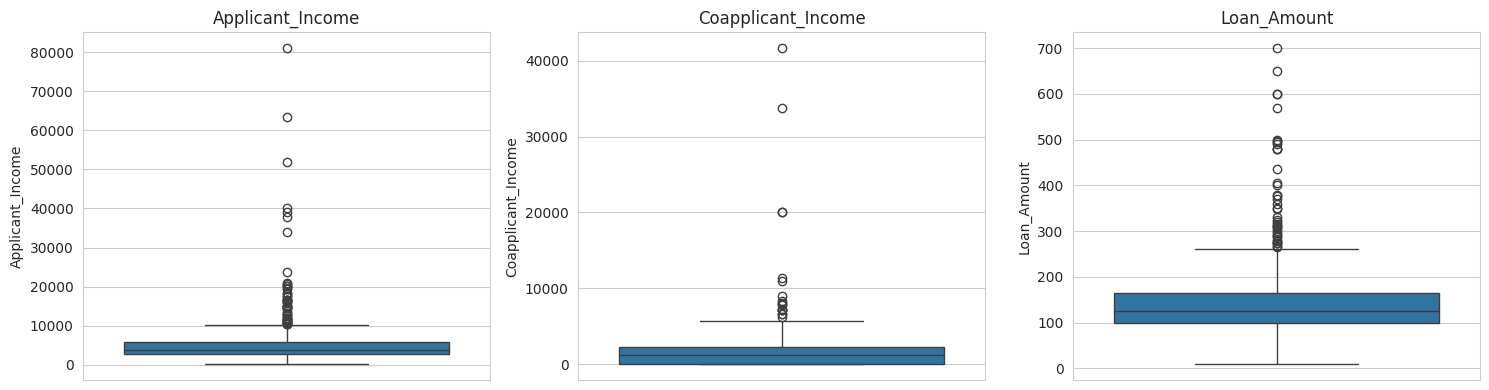

In [ ]:
#Outlier Detection (Boxplots,IQR)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [ ]:
def count_outliers_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper

for col in ["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]:
    n, low, up = count_outliers_iqr(df[col])
    print(f"{col}: {n} outliers (valid range {low:.0f} to {up:.0f})")


Applicant_Income: 50 outliers (valid range -1499 to 10171)
Coapplicant_Income: 18 outliers (valid range -3446 to 5743)
Loan_Amount: 41 outliers (valid range -2 to 265)


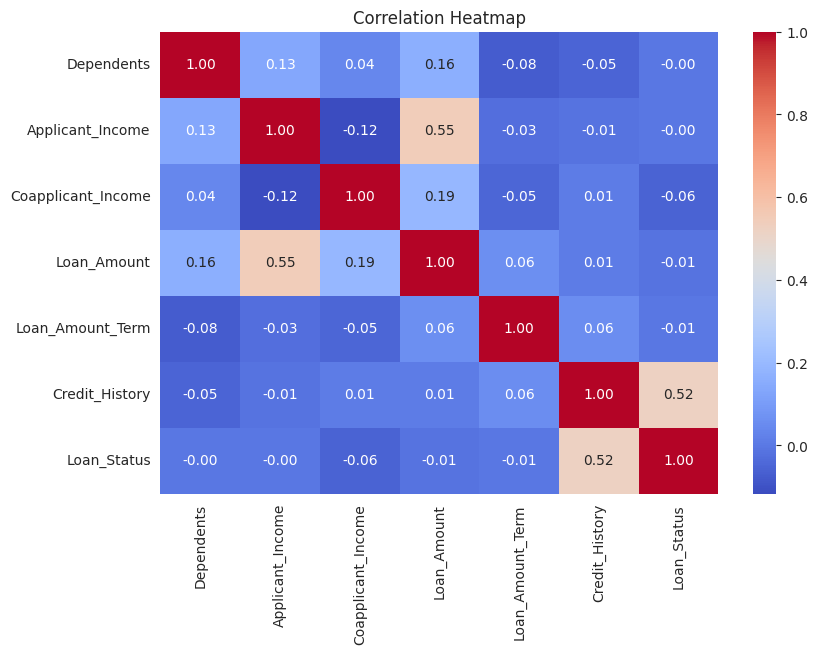

In [ ]:
 #Correlation Analysis


# Temporary numeric target just for correlation
corr_df = df.copy()
corr_df["Loan_Status"] = corr_df["Loan_Status"].map({"Y": 1, "N": 0})

plt.figure(figsize=(9, 6))
sns.heatmap(corr_df.select_dtypes(include=np.number).corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Outlier Detection and removal

In [ ]:
#Outlier Treatment
# Incomes and loan amounts are highly right-skewed. They are real values (not errors),

for col in ["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]:
    _, low, up = count_outliers_iqr(df[col])
    df[col] = df[col].clip(lower=max(low, 0), upper=up)

df[["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Applicant_Income,614.0,4617.111564,2479.851729,150.0,2877.5,3812.5,5795.00,10171.250
Coapplicant_Income,614.0,1419.702231,1624.605892,0.0,0.0,1188.5,2297.25,5743.125
Loan_Amount,614.0,133.861360,60.138124,9.0,98.0,125.0,164.75,264.875


# **Feature Engineering**

In [ ]:
#Total income of the household
df["Total_Income"] = df["Applicant_Income"] + df["Coapplicant_Income"]

In [ ]:
#EMI = monthly installment (Loan_Amount is in thousands, term is in months)
df["EMI"] = df["Loan_Amount"] / df["Loan_Amount_Term"]

In [ ]:
#Balance income left after paying EMI (EMI in thousands -> multiply by 1000)
df["Balance_Income"] = df["Total_Income"] - df["EMI"] * 1000

In [ ]:
#Loan amount compared to income
df["Loan_to_Income"] = df["Loan_Amount"] / df["Total_Income"]

In [ ]:
#Has co-applicant flag
df["Has_Coapplicant"] = (df["Coapplicant_Income"] > 0).astype(int)

In [ ]:
#Log transform of income to reduce skewness
df["Total_Income_log"] = np.log1p(df["Total_Income"])
df[["Total_Income", "EMI", "Balance_Income", "Loan_to_Income",
    "Has_Coapplicant", "Total_Income_log"]].head()

,Total_Income,EMI,Balance_Income,Loan_to_Income,Has_Coapplicant,Total_Income_log
0,2378.0,0.025000,2353.000000,0.003785,0,7.774436
1,2385.0,0.141667,2243.333333,0.007128,1,7.777374
2,3620.0,0.208333,3411.666667,0.006906,0,8.194506
3,3459.0,0.208333,3250.666667,0.007228,0,8.149024
4,6500.0,0.072222,6427.777778,0.004000,1,8.779711


In [ ]:
# Check the skew improvement
print("Skew Total_Income:", round(df["Total_Income"].skew(), 2),
      "->", round(df["Total_Income_log"].skew(), 2))

Skew Total_Income: 0.98 -> 0.0


In [ ]:
#Encoding Categorical Variables


df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})
df["Married"] = df["Married"].map({"Yes": 1, "No": 0})
df["Education"] = df["Education"].map({"Graduate": 1, "Not Graduate": 0})
df["Self_Employed"] = df["Self_Employed"].map({"Yes": 1, "No": 0})

#Target
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

In [ ]:
# Property_Area has 3 categories with no order -> One-Hot Encoding
df = pd.get_dummies(df, columns=["Property_Area"], drop_first=True, dtype=int)

df.head()

,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Loan_Status,Total_Income,EMI,Balance_Income,Loan_to_Income,Has_Coapplicant,Total_Income_log,Property_Area_Semiurban,Property_Area_Urban
0,0,0,0,1,0,2378.0,0.0,9.0,360,1,0,2378.0,0.025000,2353.000000,0.003785,0,7.774436,0,1
1,1,1,2,1,0,1299.0,1086.0,17.0,120,1,1,2385.0,0.141667,2243.333333,0.007128,1,7.777374,0,1
2,1,0,0,0,0,3620.0,0.0,25.0,120,1,1,3620.0,0.208333,3411.666667,0.006906,0,8.194506,1,0
3,1,1,0,1,1,3459.0,0.0,25.0,120,1,1,3459.0,0.208333,3250.666667,0.007228,0,8.149024,1,0
4,1,1,1,1,0,5468.0,1032.0,26.0,360,1,1,6500.0,0.072222,6427.777778,0.004000,1,8.779711,1,0


#**Encoding, Feature Selection and Train/Test Split**
Binary and one-hot encoding, dropped redundant columns, stratified 80/20 split and scaling.

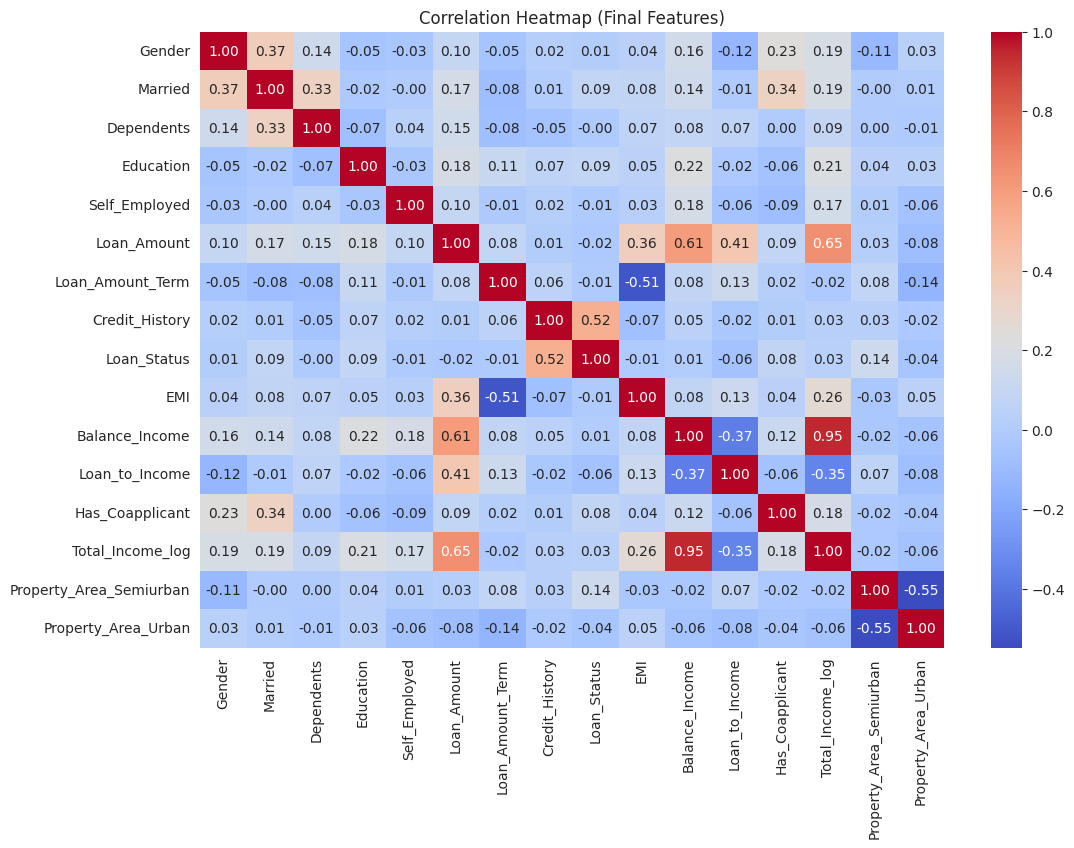

,Loan_Status
Loan_Status,1.000000
Credit_History,0.523961
Property_Area_Semiurban,0.136540
Married,0.086673
Education,0.085884
Has_Coapplicant,0.075165
Total_Income_log,0.033306
Gender,0.009357
Balance_Income,0.008444
Dependents,-0.004387


In [ ]:
#Feature Selection (Drop Redundant Columns)

df_final = df.drop(columns=["Applicant_Income", "Coapplicant_Income", "Total_Income"])

plt.figure(figsize=(12, 8))
sns.heatmap(df_final.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (Final Features)")
plt.show()

df_final.corr()["Loan_Status"].sort_values(ascending=False)

In [ ]:
#Train-Test Split and Scaling

X = df_final.drop(columns=["Loan_Status"])
y = df_final["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), " Test class ratio:", y_test.mean().round(3))


scale_cols = ["Dependents", "Loan_Amount", "Loan_Amount_Term", "EMI",
              "Balance_Income", "Loan_to_Income", "Total_Income_log"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

X_train_scaled.head()

Train: (491, 15)  Test: (123, 15)
Train class ratio: 0.686  Test class ratio: 0.691


,Gender,Married,Dependents,Education,Self_Employed,Loan_Amount,Loan_Amount_Term,Credit_History,EMI,Balance_Income,Loan_to_Income,Has_Coapplicant,Total_Income_log,Property_Area_Semiurban,Property_Area_Urban
149,1,1,2.615233,1,0,-0.549717,0.288419,1,-0.335017,-0.446472,-0.252957,0,-0.357984,1,0
234,1,1,-0.685742,0,0,-0.297149,0.288419,1,-0.249178,-0.511960,0.224058,1,-0.420774,0,1
468,1,1,0.139502,1,0,0.797312,0.288419,0,0.122789,2.411499,-1.054837,1,1.871499,0,1
502,1,0,-0.685742,1,1,0.999367,0.288419,0,0.191459,1.618843,-0.554323,0,1.456115,0,1
264,1,1,-0.685742,1,0,-0.212960,0.288419,1,-0.220566,-0.465666,0.268774,1,-0.354489,0,1


In [ ]:
#Saving the Processed Data

df_final.to_csv("loan_processed.csv", index=False)

train_out = X_train_scaled.copy(); train_out["Loan_Status"] = y_train.values
test_out = X_test_scaled.copy();   test_out["Loan_Status"] = y_test.values
train_out.to_csv("train_processed.csv", index=False)
test_out.to_csv("test_processed.csv", index=False)

print("Final dataset shape:", df_final.shape)
print("Processed loan file with train and testing are saved.")


Final dataset shape: (614, 16)
Processed loan file with train and testing are saved.


#**Key Observations and Insights**


The dataset contains 614 applicants with no missing values or duplicate rows. The target is moderately imbalanced, with about 69% of loans approved and 31% rejected, so a stratified split was used (both train and test keep roughly the same 69% approval ratio). Credit history is by far the strongest predictor: applicants with a good credit history were approved about 79% of the time, compared with only about 11% for those without one, and it has the highest correlation with Loan_Status (0.52). Property area also matters, as Semiurban applicants were approved most often (about 77%), while Urban applicants were approved least (about 66%). Married applicants, graduates and applicants with a co-applicant showed slightly higher approval rates (about 72%, 71% and 72%), but Gender and Self_Employed had almost no effect. The raw income and loan amount columns were strongly right-skewed with several outliers, which were capped using the IQR method, and a log transform of total income reduced the skewness. The engineered features (EMI, Balance_Income, Loan_to_Income) show weak linear correlation with the target, so their usefulness will be checked during modelling. Overall, the data is clean and ready for model training in the next assignment.